# Notebook 07 — Paired Rainfall Quality and Geographic Model Ablation
**Malaysia Landslide FYP · Companion to Notebook 06 · Exploratory only**

Goals: identify whether (a) rainfall itself, (b) temporal measurement quality, or (c) representation/redundancy explains static-vs-temporal performance. All four feature families use **exactly the same temporal-eligible 643 case groups + 1,286 matched controls**, subject to frozen manifest train/heldout selection. Outputs isolated to `outputs/paired_rainfall_investigation/`.

**Safeguards:** no writes to the original inventories, sidecars or model results; no test holdout predictions, tuning or evaluation. Only run paired model fitting after explicit quality clearance. Repeatedly inspected 5-km geographic folds mean all improvements are exploratory. Parent-case 50-km blocks do **not** imply strict actual-location block disjointness.


**Final run behavior:** Section 6 now executes the paired experiments automatically when frozen inputs and measured numerical quality checks pass. The timing provenance flag remains FALSE unless independently verified, and all resulting metrics are explicitly marked exploratory. Expect nested 3-fold CV to take some time. No historical held-out evaluation is performed.


## 0 — Configuration, dependencies and frozen inputs

In [1]:
from pathlib import Path
import json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.neighbors import BallTree
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score,average_precision_score,accuracy_score,precision_score,recall_score,f1_score,balanced_accuracy_score
from pyproj import Transformer

ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
           if (p/'data/processed/modelling/temporal_model_dataset.csv').is_file()),None)
if ROOT is None: raise FileNotFoundError('Open notebook from FYP project root with data/processed/modelling/temporal_model_dataset.csv')
OUT=ROOT/'outputs/paired_rainfall_investigation';OUT.mkdir(parents=True,exist_ok=True)
BASE=ROOT/'data/processed/modelling/temporal_model_dataset.csv'
SIDECAR=ROOT/'data/processed/features/historical_environmental_enhancement_recovery_REVIEW.csv'
ORIGINAL=ROOT/'data/processed/features/historical_environmental_enhancement.csv'
MANIFEST=ROOT/'outputs/model_evaluation/spatial_partition_manifest.csv'
SEED=2026; BLOCK_KM=50; EMBARGO_KM=5.0; N_FOLDS=3
RUN_PAIRED_MODELS=True  # Run paired TRAINING-only CV now and display metrics; exploratory, NOT independent validation.
TEMPORAL_PROVENANCE_CONFIRMED=False  # Keep False until event dates/IMERG coverage explicitly verified.
ALLOW_EXPLORATORY_UNVERIFIED_TIMING=True  # Explicit allowance: inspect training-only metrics, NEVER claim validated timing.
ALLOW_INCOMPLETE_ENHANCEMENT=False  # Do not silently substitute a different baseline.
print('Project:',ROOT,'| output:',OUT)
print('Model experiment enabled?',RUN_PAIRED_MODELS)


Project: C:\landslide_fyp | output: C:\landslide_fyp\outputs\paired_rainfall_investigation
Model experiment enabled? True


## 1 — Load the paired cohort; validate complete groups and untouched holdout

In [2]:
raw=pd.read_csv(BASE,low_memory=False)
needed={'sample_id','matched_event_id','event_candidate_id','reference_date','target','latitude','longitude'}
if not needed.issubset(raw):raise ValueError(f'Missing mandatory columns {sorted(needed-set(raw))}')
assert raw.sample_id.is_unique,'Sample IDs duplicate'
assert raw.target.isin([0,1]).all(),'Only binary labels allowed'
assert raw[['latitude','longitude']].notna().all().all(),'Missing geographic coordinates'
trip=raw.groupby('matched_event_id').agg(n=('target','size'),cases=('target','sum'),dates=('reference_date','nunique'),parent_ids=('event_candidate_id','nunique'))
assert trip.n.eq(3).all() and trip.cases.eq(1).all(),'A 1-case/2-control group is incomplete'
assert trip.dates.eq(1).all(),'Case/control reference-date mismatch'
case_ids=raw.loc[raw.target.eq(1), ['matched_event_id','event_candidate_id']].copy()
assert case_ids.event_candidate_id.notna().all() and (case_ids.event_candidate_id.astype(str)==case_ids.matched_event_id.astype(str)).all(), 'Case parent IDs do not match group IDs'
assert raw.loc[raw.target.eq(0),'event_candidate_id'].isna().all(), 'Some controls unexpectedly carry landslide event IDs; check schema' 
assert pd.to_datetime(raw.reference_date,errors='coerce').notna().all(),'Unparseable reference date'
assert MANIFEST.exists(),'Frozen spatial_partition_manifest.csv missing; NEVER generate a new holdout split'
man=pd.read_csv(MANIFEST,dtype={'sample_id':str,'matched_event_id':str,'spatial_block_id':str})
need_manifest={'branch','sample_id','matched_event_id','spatial_block_id','partition'}
assert need_manifest.issubset(man),'Frozen manifest missing required columns'
man=man.loc[man.branch.eq('temporal')].copy()
assert man.sample_id.is_unique and set(man.sample_id)==set(raw.sample_id.astype(str)),'Manifest sample universe differs'
assert man.partition.isin(['train','heldout']).all(),'Invalid partition labels'
assert not man.spatial_block_id.isna().any(),'Missing spatial block'
base=raw.rename(columns={'spatial_block_id':'original_spatial_block_id'}).merge(
    man[['sample_id','matched_event_id','spatial_block_id','partition']].rename(columns={'matched_event_id':'manifest_parent'}),
    on='sample_id',validate='one_to_one',how='inner',sort=False)
assert base.matched_event_id.astype(str).equals(base.manifest_parent.astype(str))
assert base.groupby('matched_event_id').partition.nunique().eq(1).all(),'Manifest splits matched controls from cases'
# Heldout rows are counted for audit only; no feature summaries, models or predictions are computed on them.
partition_counts=base.groupby(['partition','target']).size().unstack(fill_value=0).reset_index()
partition_counts.to_csv(OUT/'01_frozen_partition_counts.csv',index=False)
display(partition_counts)
train=base.loc[base.partition.eq('train')].copy().reset_index(drop=True)
assert train.target.nunique()==2 and train.matched_event_id.nunique()>=N_FOLDS
print('Complete full-dataset case groups:',len(trip),'| training-only rows:',len(train))


target,partition,0,1
0,heldout,428,214
1,train,858,429


Complete full-dataset case groups: 643 | training-only rows: 1287


## 2 — Restore the Notebook 04 reviewed environmental sidecar
Use the **same reviewed enhancement file and no geology/fault inputs** as Notebook 04. We never change any already observed enhancement values. A sidecar containing unavailable values is not a reason to reconstruct or impute them from future data; actual model pipelines will impute inside each training fold.

In [3]:
ENHANCEMENT={
 'vegetation':['ndvi_pre_event','ndvi_change_2y'],
 'forest_loss':['forest_loss_5y_250m_pct'],
 'runoff':['runoff_7d_mm','runoff_30d_mm'],
 'hydrological_terrain':['merit_upstream_area_km2','merit_hand_m']}
E_COLS=sum(ENHANCEMENT.values(),[])
sidecar_status=[]
if SIDECAR.exists() and ORIGINAL.exists():
    revised=pd.read_csv(SIDECAR,low_memory=False)
    original=pd.read_csv(ORIGINAL,low_memory=False)
    assert revised.sample_id.is_unique and original.sample_id.is_unique
    assert revised.sample_id.astype(str).equals(original.sample_id.astype(str))
    assert set(E_COLS).issubset(revised.columns),'Reviewed sidecar incomplete'
    for col in original.columns:
        if col not in E_COLS:
            assert revised[col].equals(original[col]),f'Unreviewed change to sidecar provenance field {col}'
        else:
            a=pd.to_numeric(original[col],errors='coerce');b=pd.to_numeric(revised[col],errors='coerce')
            assert np.allclose(a[a.notna()],b[a.notna()],atol=1e-8,rtol=0,equal_nan=True),f'Changed existing observations in {col}'
    extra=revised[['sample_id']+E_COLS].copy()
    for col in E_COLS:extra[col]=pd.to_numeric(extra[col],errors='coerce').replace([np.inf,-np.inf],np.nan)
    rows_before=len(train)
    train=train.merge(extra,on='sample_id',how='left',validate='one_to_one',sort=False)
    assert len(train)==rows_before
    sidecar_status.append({'status':'VERIFIED','path':str(SIDECAR),'missing_sample_ids':int((~train.sample_id.isin(extra.sample_id)).sum())})
else:
    sidecar_status.append({'status':'MISSING','path':str(SIDECAR),'missing_sample_ids':len(train)})
    for col in E_COLS:train[col]=np.nan
pd.DataFrame(sidecar_status).to_csv(OUT/'02_reviewed_enhancement_provenance.csv',index=False)
display(pd.DataFrame(sidecar_status))
if sidecar_status[0]['status']!='VERIFIED' and not ALLOW_INCOMPLETE_ENHANCEMENT:
    print('MODEL RUN IS BLOCKED until the same Notebook 04 reviewed sidecar is available.')


,status,path,missing_sample_ids
0,VERIFIED,C:\landslide_fyp\data\processed\features\histo...,0


## 3 — Data quality: windows, missingness, skew, extremes and case/control distribution

,feature,rows,nonmissing,missing_pct,negative_n,zero_n,min,median,p95,p99,max,skewness
0,rain_1d_mm,1287,1287,0.000,0,34,0.000,15.175,166.195,213.158,248.360,1.309
1,rain_3d_mm,1287,1287,0.000,0,13,0.000,55.495,245.075,347.690,520.930,1.507
2,rain_7d_mm,1287,1287,0.000,0,5,0.000,110.230,307.991,410.068,737.860,1.883
3,rain_14d_mm,1287,1287,0.000,0,1,0.000,147.440,389.057,538.905,1142.355,2.510
4,rain_30d_mm,1287,1287,0.000,0,0,5.670,310.435,616.513,772.310,1237.720,1.198
5,soil_moisture_7d_m3m3,1287,1287,0.000,0,0,0.159,0.467,0.483,0.489,0.587,-2.540
6,runoff_7d_mm,1287,1283,0.311,0,0,0.001,11.773,45.923,88.097,215.517,3.931
7,runoff_30d_mm,1287,1283,0.311,0,0,0.165,30.249,103.714,253.183,416.183,4.173


{'bad_window_order': 0, 'any_negative_rain': 0, 'any_missing_rain': 0}


,feature,target,n,median,mean,q25,q75
0,rain_1d_mm,0,858,15.174999,46.517837,7.511250,75.644998
1,rain_1d_mm,1,429,15.055000,47.357388,8.615000,82.274998
2,rain_3d_mm,0,858,55.599999,91.012918,34.314999,141.374996
3,rain_3d_mm,1,429,53.754999,89.769042,39.374999,128.954997
4,rain_7d_mm,0,858,107.714997,127.782567,76.526248,159.284997
5,rain_7d_mm,1,429,112.504998,127.243342,87.074998,133.709997
6,rain_14d_mm,0,858,148.457497,176.985322,113.361247,217.278745
7,rain_14d_mm,1,429,147.439997,176.080276,118.089997,198.464994
8,rain_30d_mm,0,858,306.839994,314.899398,183.563746,389.464991
9,rain_30d_mm,1,429,316.194993,320.853268,189.819996,382.249992


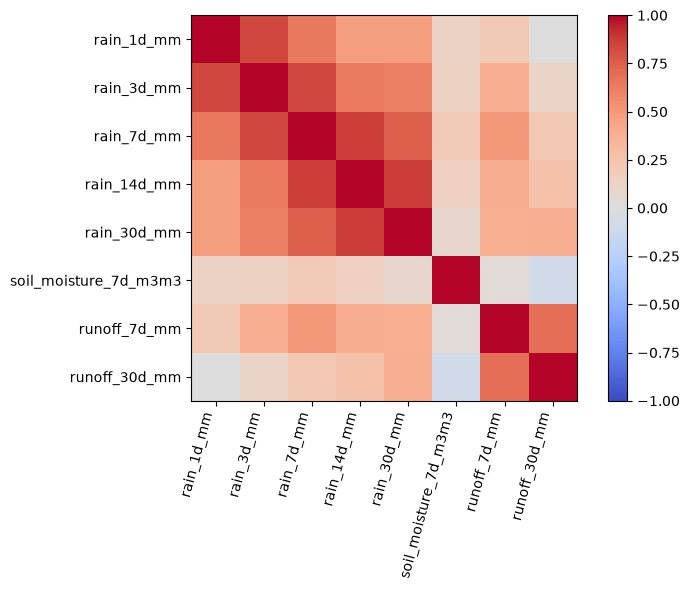

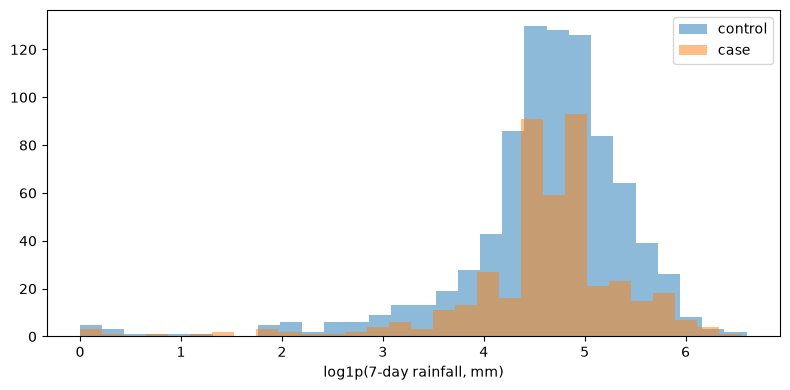

In [4]:
RAIN=[f'rain_{d}d_mm' for d in (1,3,7,14,30)]
MOIST=['soil_moisture_7d_m3m3']
RUNOFF=ENHANCEMENT['runoff']
for f in RAIN+MOIST:
    if f not in train:raise ValueError(f'Required temporal predictor missing: {f}')
qa=[]
for f in RAIN+MOIST+RUNOFF:
    x=pd.to_numeric(train[f],errors='coerce').replace([np.inf,-np.inf],np.nan)
    qa.append({'feature':f,'rows':len(x),'nonmissing':int(x.notna().sum()),'missing_pct':100*x.isna().mean(),
               'negative_n':int(x.lt(0).sum()),'zero_n':int(x.eq(0).sum()),
               'min':x.min(),'median':x.median(),'p95':x.quantile(.95),'p99':x.quantile(.99),
               'max':x.max(),'skewness':x.skew()})
quality=pd.DataFrame(qa);quality.to_csv(OUT/'03_rainfall_hydrology_data_quality.csv',index=False);display(quality.round(3))
rain_values=train[RAIN].apply(pd.to_numeric,errors='coerce')
violations=(rain_values.diff(axis=1).iloc[:,1:] < -1e-7).any(axis=1)
quality_flags={'bad_window_order':int(violations.sum()),
               'any_negative_rain':int(rain_values.lt(0).any(axis=1).sum()),
               'any_missing_rain':int(rain_values.isna().any(axis=1).sum())}
(OUT/'04_rainfall_quality_flags.json').write_text(json.dumps(quality_flags,indent=2))
print(quality_flags)
long=[]
for feat in RAIN+MOIST+RUNOFF:
    for cls,g in train.groupby('target'):
        x=pd.to_numeric(g[feat],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
        long.append(dict(feature=feat,target=int(cls),n=len(x),median=x.median(),mean=x.mean(),q25=x.quantile(.25),q75=x.quantile(.75)))
summary=pd.DataFrame(long);summary.to_csv(OUT/'05_case_control_hydrological_summary.csv',index=False);display(summary)
cor=train[RAIN+MOIST+RUNOFF].apply(pd.to_numeric,errors='coerce').corr()
cor.to_csv(OUT/'06_temporal_feature_correlations.csv')
fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(cor.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(cor)),cor.columns,rotation=75,ha='right');ax.set_yticks(range(len(cor)),cor.index);fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(OUT/'07_temporal_correlation_heatmap.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4));[ax.hist(np.log1p(pd.to_numeric(train.loc[train.target.eq(t),'rain_7d_mm'],errors='coerce').clip(lower=0).dropna()),bins=30,alpha=.5,label='case' if t else 'control') for t in (0,1)];ax.legend();ax.set_xlabel('log1p(7-day rainfall, mm)');fig.tight_layout();fig.savefig(OUT/'08_log_rain_7d_distributions.png',dpi=160);plt.show()



## 4 — Parent-date rainfall similarity and geographic/source heterogeneity

In [5]:
rows=[]
for f in RAIN+MOIST:
    for eid,g in train.groupby('matched_event_id'):
        v=pd.to_numeric(g.loc[g.target.eq(1),f],errors='coerce')
        b=pd.to_numeric(g.loc[g.target.eq(0),f],errors='coerce')
        if len(v)==1 and len(b)==2:
            rows.append(dict(matched_event_id=eid,feature=f,case_value=v.iloc[0],control_mean=b.mean(),
                             case_minus_control=v.iloc[0]-b.mean(),control_range=b.max()-b.min(),
                             source=g.source.iloc[0] if 'source' in g else '',date=g.reference_date.iloc[0]))
paired=pd.DataFrame(rows);paired.to_csv(OUT/'09_matched_case_control_temporal_contrast.csv',index=False)
comparison=paired.groupby('feature',as_index=False).agg(groups=('case_minus_control','size'),
  median_case_minus_control=('case_minus_control','median'),
  mean_case_minus_control=('case_minus_control','mean'),
  median_control_range=('control_range','median'),
  median_absolute_difference=('case_minus_control',lambda s:s.abs().median()))
comparison.to_csv(OUT/'10_paired_temporal_contrast_summary.csv',index=False);display(comparison)
source_summary=paired.groupby(['feature','source'],as_index=False).agg(groups=('matched_event_id','nunique'),median_difference=('case_minus_control','median'))
source_summary.to_csv(OUT/'11_source_temporal_contrast.csv',index=False)
print('Differences reflect satellite grid resolution, matched design and physical context; no causal attribution.')


,feature,groups,median_case_minus_control,mean_case_minus_control,median_control_range,median_absolute_difference
0,rain_14d_mm,429,-1.575000,-0.905047,22.27500,21.467500
1,rain_1d_mm,429,-0.132500,0.839551,7.01500,4.877501
2,rain_30d_mm,429,6.247500,5.953869,32.02500,27.187499
3,rain_3d_mm,429,-3.167499,-1.243875,14.20500,11.692499
4,rain_7d_mm,429,-2.842500,-0.539225,20.47000,17.105000
5,soil_moisture_7d_m3m3,429,-0.000714,0.000067,0.00873,0.007303


Differences reflect satellite grid resolution, matched design and physical context; no causal attribution.


## 5 — Exact Notebook 04 geographic-fold protocol (training partition only)
Uses the **frozen manifest's parent-case block ID**, `StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=2026)`, a 5 km Haversine nearest-neighbor embargo between **actual** train/validation coordinates, and purges entire matched triplets. Inner folds similarly use seed `2026 + outer_fold`. Shared actual 50 km blocks are audited but **not forbidden**. No independent holdout evaluation.

In [6]:
EARTH_KM=6371.0088
projection=Transformer.from_crs('EPSG:4326','EPSG:6933',always_xy=True)
def actual_blocks(frame):
    xx,yy=projection.transform(frame.longitude.to_numpy(float),frame.latitude.to_numpy(float))
    return np.floor(np.asarray(xx)/(BLOCK_KM*1000)).astype(int).astype(str)+'_'+np.floor(np.asarray(yy)/(BLOCK_KM*1000)).astype(int).astype(str)
def embargo_folds(frame,n_splits,seed,stage):
    f=frame.reset_index(drop=True)
    parent=f.spatial_block_id.astype(str)
    assert f.assign(_parent=parent).groupby('matched_event_id')._parent.nunique().eq(1).all()
    coords=np.radians(f[['latitude','longitude']].to_numpy(float))
    actual=np.asarray(actual_blocks(f))
    raw_folds=StratifiedGroupKFold(n_splits=n_splits,shuffle=True,random_state=seed)
    result=[];aud=[]
    for fold,(ti,vi) in enumerate(raw_folds.split(f,f.target,groups=parent),1):
        nearest=BallTree(coords[vi],metric='haversine').query(coords[ti],k=1)[0][:,0]*EARTH_KM
        purge=set(f.iloc[ti[np.where(nearest<EMBARGO_KM-1e-8)[0]]].matched_event_id.astype(str))
        keep=~f.iloc[ti].matched_event_id.astype(str).isin(purge).to_numpy()
        tr=ti[keep]
        assert len(tr)>0 and f.iloc[tr].target.nunique()==2 and f.iloc[vi].target.nunique()==2
        assert f.iloc[tr].matched_event_id.nunique()>=10
        assert not (set(f.iloc[tr].matched_event_id)&set(f.iloc[vi].matched_event_id))
        assert f.iloc[tr].groupby('matched_event_id').size().eq(3).all()
        assert f.iloc[vi].groupby('matched_event_id').size().eq(3).all()
        distance=float(BallTree(coords[vi],metric='haversine').query(coords[tr],k=1)[0].min()*EARTH_KM)
        assert distance>=EMBARGO_KM-1e-7
        shared=len(set(actual[tr]) & set(actual[vi]))
        result.append((tr,vi))
        aud.append(dict(stage=stage,fold=fold,seed=seed,train_rows=len(tr),validation_rows=len(vi),
                        embargo_removed_rows=len(ti)-len(tr),min_distance_km=distance,
                        shared_actual_50km_blocks=shared,shared_matched_groups=0))
    return result,pd.DataFrame(aud)
outer,audit=embargo_folds(train,N_FOLDS,SEED,'outer')
audit.to_csv(OUT/'12_frozen_parent_block_geographic_audit.csv',index=False);display(audit)
# Group + sample-ID manifests permit strict per-configuration equality audits.
fold_rows=[]
for k,(ti,vi) in enumerate(outer,1):
    for split,ids in [('train',ti),('validation',vi)]:
        fold_rows.extend(dict(fold=k,split=split,sample_id=str(x)) for x in train.iloc[ids].sample_id)
pd.DataFrame(fold_rows).to_csv(OUT/'13_outer_fold_sample_manifest.csv',index=False)


,stage,fold,seed,train_rows,validation_rows,embargo_removed_rows,min_distance_km,shared_actual_50km_blocks,shared_matched_groups
0,outer,1,2026,651,429,207,5.198069,21,0
1,outer,2,2026,771,429,87,5.140070,33,0
2,outer,3,2026,486,429,372,5.011056,41,0


## 6 — Four paired configurations and optional bounded model run
A: static only. B: static + five rainfall windows. C: static + soil moisture and runoff. D: all verified temporal. All share the exact same observations/folds. Only Linear SVM and Logistic Regression, with Notebook 04's balanced weights, C grid and default decision thresholds. Transformations and imputation are fit **inside** training folds.

**Important:** `RUN_PAIRED_MODELS` and `TEMPORAL_PROVENANCE_CONFIRMED` must both be True. Do not bypass a failed quality audit. This cell may take time: outer × inner geographic CV is intentionally stringent.

In [7]:
STATIC_NUM=['elevation_m','slope_deg','aspect_sin','aspect_cos','soil_clay_surface',
            'soil_sand_surface','soil_silt_surface','soil_bdod_surface','road_distance_m',
            'waterway_distance_m','ndvi_pre_event','ndvi_change_2y',
            'forest_loss_5y_250m_pct','merit_upstream_area_km2','merit_hand_m']
CATEGORICAL=['landcover_pre_event_class']
FEATURE_CONFIG={
 'A_static':STATIC_NUM,
 'B_static_rain':STATIC_NUM+RAIN,
 'C_static_moisture_runoff':STATIC_NUM+MOIST+RUNOFF,
 'D_static_all_temporal':STATIC_NUM+RAIN+MOIST+RUNOFF}
missing={k:[c for c in cols+CATEGORICAL if c not in train.columns] for k,cols in FEATURE_CONFIG.items()}
if any(missing.values()):raise KeyError(f'Existing Notebook 04 features absent: {missing}')
config_audit=pd.DataFrame([{'config':k,'n_numeric':len(v),'n_categorical':len(CATEGORICAL),
                            'n_rows':len(train),'n_case_groups':int(train.target.sum()),
                            'missing_predictor_cells':int(train[v+CATEGORICAL].isna().sum().sum())}
                          for k,v in FEATURE_CONFIG.items()]);display(config_audit)
config_audit.to_csv(OUT/'14_paired_configuration_audit.csv',index=False)
required_quality=(quality.set_index('feature').loc[RAIN,'negative_n'].sum()==0 and
                  quality_flags['bad_window_order']==0 and quality_flags['any_missing_rain']==0)
model_gate={'run_requested':RUN_PAIRED_MODELS,'temporal_provenance_confirmed':TEMPORAL_PROVENANCE_CONFIRMED,
            'exploratory_unverified_timing_allowed':ALLOW_EXPLORATORY_UNVERIFIED_TIMING,
            'enhancement_verified':sidecar_status[0]['status']=='VERIFIED',
            'rain_values_quality_pass':bool(required_quality),
            'train_cohort_rows':len(train),'holdout_used_for_fit':False,
            'allowed':bool(RUN_PAIRED_MODELS and (TEMPORAL_PROVENANCE_CONFIRMED or ALLOW_EXPLORATORY_UNVERIFIED_TIMING) and
                           sidecar_status[0]['status']=='VERIFIED' and required_quality),
            'results_status':'EXPLORATORY_UNVERIFIED_TEMPORAL_PROVENANCE' if not TEMPORAL_PROVENANCE_CONFIRMED else 'EXPLORATORY_PREVIOUSLY_INSPECTED_SPATIAL_FOLDS'}
(OUT/'15_model_run_gate.json').write_text(json.dumps(model_gate,indent=2))
print('Model run gate:',model_gate)


,config,n_numeric,n_categorical,n_rows,n_case_groups,missing_predictor_cells
0,A_static,15,1,1287,429,174
1,B_static_rain,20,1,1287,429,174
2,C_static_moisture_runoff,18,1,1287,429,182
3,D_static_all_temporal,23,1,1287,429,182


Model run gate: {'run_requested': True, 'temporal_provenance_confirmed': False, 'exploratory_unverified_timing_allowed': True, 'enhancement_verified': True, 'rain_values_quality_pass': True, 'train_cohort_rows': 1287, 'holdout_used_for_fit': False, 'allowed': True, 'results_status': 'EXPLORATORY_UNVERIFIED_TEMPORAL_PROVENANCE'}


In [8]:
def pipeline_for(name,numeric):
    num=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
                  ('scale',StandardScaler())])
    cat=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Unknown',keep_empty_features=True)),
                  ('onehot',OneHotEncoder(handle_unknown='ignore'))])
    prep=ColumnTransformer([('numeric',num,numeric),('categorical',cat,CATEGORICAL)],sparse_threshold=0.0)
    est=(LogisticRegression(class_weight='balanced',max_iter=4000,random_state=SEED) if name=='LogisticRegression'
         else SVC(kernel='linear',class_weight='balanced',probability=False,cache_size=500))
    return Pipeline([('prepare',prep),('model',est)])

def metric_set(y,scores,pred):
    return {'roc_auc':roc_auc_score(y,scores),'pr_auc':average_precision_score(y,scores),
            'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),
            'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,pred)}

records=[];inner_audits=[]
if model_gate['allowed']:
    for fold,(ti,vi) in enumerate(outer,1):
        tr,va=train.iloc[ti].reset_index(drop=True),train.iloc[vi].reset_index(drop=True)
        inner,inner_geo=embargo_folds(tr,N_FOLDS,SEED+fold,f'inner_outer_{fold}')
        inner_audits.append(inner_geo)
        for config,cols in FEATURE_CONFIG.items():
            xcols=cols+CATEGORICAL
            Xtr=tr[xcols].copy();Xva=va[xcols].copy()
            # Some source land-cover codes are numeric; encode them as categorical strings.
            for categorical_col in CATEGORICAL:
                Xtr[categorical_col]=Xtr[categorical_col].astype('string').fillna('Unknown').astype(str)
                Xva[categorical_col]=Xva[categorical_col].astype('string').fillna('Unknown').astype(str)
            for name in ('LogisticRegression','LinearSVM'):
                model=pipeline_for(name,cols)
                search=GridSearchCV(model,{'model__C':[.01,.1,1.]},cv=inner,scoring='roc_auc',n_jobs=1,refit=True,error_score='raise')
                search.fit(Xtr,tr.target)
                best=search.best_estimator_
                tr_rank=(best.predict_proba(Xtr)[:,1] if name=='LogisticRegression' else best.decision_function(Xtr))
                va_rank=(best.predict_proba(Xva)[:,1] if name=='LogisticRegression' else best.decision_function(Xva))
                threshold=0.5 if name=='LogisticRegression' else 0.0
                result=metric_set(va.target.to_numpy(),va_rank,(va_rank>=threshold).astype(int))
                train_auc=roc_auc_score(tr.target.to_numpy(),tr_rank)
                records.append(dict(outer_fold=fold,configuration=config,algorithm=name,
                                    n_train=len(tr),n_valid=len(va),train_auc=train_auc,
                                    train_validation_auc_gap=train_auc-result['roc_auc'],
                                    selected_C=float(search.best_params_['model__C']),
                                    inner_auc=float(search.best_score_),threshold=threshold,**result))
        print('Outer fold',fold,'finished; configurations share identical sample IDs and 5 km embargo.',flush=True)
    frame=pd.DataFrame(records);frame.to_csv(OUT/'16_paired_model_outer_fold_results.csv',index=False)
    pd.concat(inner_audits,ignore_index=True).to_csv(OUT/'17_inner_geographic_audit.csv',index=False)
    summ=frame.groupby(['configuration','algorithm'],as_index=False).agg(
        folds=('outer_fold','nunique'),roc_auc=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
        pr_auc=('pr_auc','mean'),accuracy=('accuracy','mean'),precision=('precision','mean'),
        recall=('recall','mean'),f1=('f1','mean'),balanced_accuracy=('balanced_accuracy','mean'),
        mean_auc_gap=('train_validation_auc_gap','mean'))
    summ.to_csv(OUT/'18_paired_model_summary.csv',index=False);display(summ.round(4))
else:
    print('No models fitted. Clear source-time provenance and review the data-quality audit before opting in.')


c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_bas

Outer fold 1 finished; configurations share identical sample IDs and 5 km embargo.


c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_bas

Outer fold 2 finished; configurations share identical sample IDs and 5 km embargo.


c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_bas

Outer fold 3 finished; configurations share identical sample IDs and 5 km embargo.


c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,configuration,algorithm,folds,roc_auc,roc_auc_sd,pr_auc,accuracy,precision,recall,f1,balanced_accuracy,mean_auc_gap
0,A_static,LinearSVM,3,0.7830,0.0681,0.6282,0.6822,0.5179,0.7413,0.6010,0.6970,0.0804
1,A_static,LogisticRegression,3,0.7767,0.0799,0.6267,0.6946,0.5275,0.7273,0.6076,0.7028,0.0912
2,B_static_rain,LinearSVM,3,0.7821,0.0843,0.6258,0.6698,0.5023,0.7949,0.6131,0.7010,0.0869
3,B_static_rain,LogisticRegression,3,0.7764,0.0834,0.6114,0.6869,0.5227,0.7669,0.6184,0.7069,0.0922
4,C_static_moisture_runoff,LinearSVM,3,0.7808,0.0799,0.6215,0.6737,0.5035,0.7413,0.5962,0.6906,0.0861
5,C_static_moisture_runoff,LogisticRegression,3,0.7792,0.0888,0.6333,0.7055,0.5437,0.7366,0.6229,0.7133,0.0952
6,D_static_all_temporal,LinearSVM,3,0.7816,0.0851,0.6170,0.6814,0.5149,0.7809,0.6184,0.7063,0.0895
7,D_static_all_temporal,LogisticRegression,3,0.7800,0.0879,0.6174,0.6946,0.5354,0.7599,0.6245,0.7110,0.0939


## 6A — Direct model metrics, improvement deltas and geographic stability
This prints **all paired metrics** for A/B/C/D with LR and Linear SVM on the exact same geographic outer folds. Improvements are calculated against **A (static-only)** within each algorithm. The rows are exploratory, because the geographic folds have already been inspected; with temporal provenance unverified the results are *not* validation of triggering rainfall. No historical held-out rows are scored.

In [9]:
# Uses Section 6 results. No model retraining here.
summary_file=OUT/'18_paired_model_summary.csv'
fold_file=OUT/'16_paired_model_outer_fold_results.csv'
if summary_file.exists() and fold_file.exists() and model_gate['allowed']:
    metrics=pd.read_csv(summary_file)
    fold_results=pd.read_csv(fold_file)
    fields=['roc_auc','pr_auc','accuracy','precision','recall','f1','balanced_accuracy']
    baseline=(metrics.loc[metrics.configuration.eq('A_static'),['algorithm']+fields]
              .set_index('algorithm'))
    for k in fields:
        metrics['delta_'+k]=metrics.apply(lambda r:r[k]-baseline.loc[r.algorithm,k],axis=1)
    metrics['status']=model_gate['results_status']
    metrics.to_csv(OUT/'19_paired_metrics_with_static_baseline_deltas_EXPLORATORY.csv',index=False)
    print('\nPAIRED GEOGRAPHIC CROSS-VALIDATION — TRAINING ONLY; NOT HELD-OUT PERFORMANCE')
    display(metrics[['algorithm','configuration']+fields+['mean_auc_gap','roc_auc_sd']].round(4))
    print('\nCHANGES AGAINST SAME-COHORT STATIC BASELINE (positive = higher metric)')
    display(metrics[['algorithm','configuration']+['delta_'+k for k in fields]].round(4))
    for alg in ['LinearSVM','LogisticRegression']:
        z=metrics.loc[metrics.algorithm.eq(alg)].copy()
        print(f'\n{alg} — compared with its own A_static baseline')
        display(z[['configuration','roc_auc','delta_roc_auc','f1','delta_f1','balanced_accuracy','delta_balanced_accuracy','mean_auc_gap','roc_auc_sd']].round(4))
    # Per-fold deltas give a sense of variation; these are not independent improvement estimates.
    reference=fold_results.loc[fold_results.configuration.eq('A_static'),['algorithm','outer_fold']+fields]
    paired_delta=fold_results.merge(reference,on=['algorithm','outer_fold'],suffixes=('','_A'),validate='many_to_one')
    for k in fields:paired_delta['delta_'+k]=paired_delta[k]-paired_delta[k+'_A']
    paired_delta[['algorithm','outer_fold','configuration']+['delta_'+k for k in fields]].to_csv(
        OUT/'20_paired_fold_level_deltas_EXPLORATORY.csv',index=False)
    print('\nIMPORTANT: Selecting a winning configuration from these examined folds biases the apparent gain.')
    if not TEMPORAL_PROVENANCE_CONFIRMED:
        print('WARNING: Event-date precision / IMERG source-time provenance remains unverified. Treat these as conditional numerical results only.')
else:
    print('No comparison metrics yet; see 15_model_run_gate.json and execution logs for the exact blocker.')


PAIRED GEOGRAPHIC CROSS-VALIDATION — TRAINING ONLY; NOT HELD-OUT PERFORMANCE


,algorithm,configuration,roc_auc,pr_auc,accuracy,precision,recall,f1,balanced_accuracy,mean_auc_gap,roc_auc_sd
0,LinearSVM,A_static,0.7830,0.6282,0.6822,0.5179,0.7413,0.6010,0.6970,0.0804,0.0681
1,LogisticRegression,A_static,0.7767,0.6267,0.6946,0.5275,0.7273,0.6076,0.7028,0.0912,0.0799
2,LinearSVM,B_static_rain,0.7821,0.6258,0.6698,0.5023,0.7949,0.6131,0.7010,0.0869,0.0843
3,LogisticRegression,B_static_rain,0.7764,0.6114,0.6869,0.5227,0.7669,0.6184,0.7069,0.0922,0.0834
4,LinearSVM,C_static_moisture_runoff,0.7808,0.6215,0.6737,0.5035,0.7413,0.5962,0.6906,0.0861,0.0799
5,LogisticRegression,C_static_moisture_runoff,0.7792,0.6333,0.7055,0.5437,0.7366,0.6229,0.7133,0.0952,0.0888
6,LinearSVM,D_static_all_temporal,0.7816,0.6170,0.6814,0.5149,0.7809,0.6184,0.7063,0.0895,0.0851
7,LogisticRegression,D_static_all_temporal,0.7800,0.6174,0.6946,0.5354,0.7599,0.6245,0.7110,0.0939,0.0879



CHANGES AGAINST SAME-COHORT STATIC BASELINE (positive = higher metric)


,algorithm,configuration,delta_roc_auc,delta_pr_auc,delta_accuracy,delta_precision,delta_recall,delta_f1,delta_balanced_accuracy
0,LinearSVM,A_static,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,LogisticRegression,A_static,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,LinearSVM,B_static_rain,-0.0009,-0.0024,-0.0124,-0.0155,0.0536,0.0121,0.0041
3,LogisticRegression,B_static_rain,-0.0004,-0.0153,-0.0078,-0.0049,0.0396,0.0108,0.0041
4,LinearSVM,C_static_moisture_runoff,-0.0022,-0.0067,-0.0085,-0.0143,0.0000,-0.0048,-0.0064
5,LogisticRegression,C_static_moisture_runoff,0.0024,0.0066,0.0109,0.0162,0.0093,0.0153,0.0105
6,LinearSVM,D_static_all_temporal,-0.0014,-0.0112,-0.0008,-0.0030,0.0396,0.0174,0.0093
7,LogisticRegression,D_static_all_temporal,0.0033,-0.0093,-0.0000,0.0078,0.0326,0.0169,0.0082



LinearSVM — compared with its own A_static baseline


,configuration,roc_auc,delta_roc_auc,f1,delta_f1,balanced_accuracy,delta_balanced_accuracy,mean_auc_gap,roc_auc_sd
0,A_static,0.7830,0.0000,0.6010,0.0000,0.6970,0.0000,0.0804,0.0681
2,B_static_rain,0.7821,-0.0009,0.6131,0.0121,0.7010,0.0041,0.0869,0.0843
4,C_static_moisture_runoff,0.7808,-0.0022,0.5962,-0.0048,0.6906,-0.0064,0.0861,0.0799
6,D_static_all_temporal,0.7816,-0.0014,0.6184,0.0174,0.7063,0.0093,0.0895,0.0851



LogisticRegression — compared with its own A_static baseline


,configuration,roc_auc,delta_roc_auc,f1,delta_f1,balanced_accuracy,delta_balanced_accuracy,mean_auc_gap,roc_auc_sd
1,A_static,0.7767,0.0000,0.6076,0.0000,0.7028,0.0000,0.0912,0.0799
3,B_static_rain,0.7764,-0.0004,0.6184,0.0108,0.7069,0.0041,0.0922,0.0834
5,C_static_moisture_runoff,0.7792,0.0024,0.6229,0.0153,0.7133,0.0105,0.0952,0.0888
7,D_static_all_temporal,0.7800,0.0033,0.6245,0.0169,0.7110,0.0082,0.0939,0.0879



IMPORTANT: Selecting a winning configuration from these examined folds biases the apparent gain.


## 7 — Optional *second-stage* rainfall representation (separate exploratory study)
Only after reviewing A–D results: choose at most one predefined alternative, such as `log1p(rainfall)` **inside the numeric pipeline** or a 7/30 rainfall-concentration ratio calculated equally for cases and controls. Do not compare many alternatives by repeatedly selecting the best outer-fold score. No model is run in this section. There is no need to re-extract Earth Engine data unless QA identifies a concrete defect.

In [10]:
x=train[['sample_id','target','rain_7d_mm','rain_30d_mm','slope_deg']].copy()
for f in ['rain_7d_mm','rain_30d_mm','slope_deg']:x[f]=pd.to_numeric(x[f],errors='coerce')
x['rain_concentration_7d_30d']=x.rain_7d_mm/x.rain_30d_mm.where(x.rain_30d_mm.gt(0))
x['rain_7d_x_slope']=x.rain_7d_mm*x.slope_deg
x['log1p_rain_7d_mm']=np.log1p(x.rain_7d_mm.clip(lower=0))
feas=x.drop(columns='sample_id').groupby('target').agg(['count','median'])
feas.to_csv(OUT/'19_candidate_rainfall_representation_availability.csv')
print('Candidate feature representation coverage (training partition only):');display(feas)
print('Exploratory candidates are NOT used in fitted A–D comparisons.')


Candidate feature representation coverage (training partition only):


rain_7d_mm             rain_30d_mm             slope_deg             \
            count      median       count      median     count     median   
target                                                                       
0             858  107.714997         858  306.839994       858   6.538092   
1             429  112.504998         429  316.194993       429  11.900707   

       rain_concentration_7d_30d           rain_7d_x_slope               \
                           count    median           count       median   
target                                                                    
0                            858  0.427280             858   687.417511   
1                            429  0.422685             429  1398.891318   

       log1p_rain_7d_mm            
                  count    median  
target                             
0                   858  4.688730  
1                   429  4.731847

Exploratory candidates are NOT used in fitted A–D comparisons.


## 8 — Interpretation and next steps

1. If rainfall (B) does not improve over A on paired observations, investigate low within-triplet rainfall contrasts, coarse satellite resolution, event-date precision, collinearity and geographically heterogeneous effects.
2. If C improves A but B does not, soil moisture/runoff may provide additional separation; inspect provenance and missingness before attributing physical meaning.
3. If D improves B or C, joint predictors may matter, but improvements on these inspected folds are **exploratory**, not independent evidence.
4. If A beats D, do not assume rainfall is unimportant physically: the outcome is **statistical contribution in this sampled susceptibility problem**, not trigger causation.
5. The frozen held-out set stays unused; all outputs are written under a **new** directory. Do not tune the 5 km buffer or resample cases to inflate metrics.
6. Notebook 06 is for raw reported triggers, credible provenance, and environmental compatibility only, **not** binary-model feature selection.
